# Exploratory Data Analysis & Data Viz: House Price Prediction 

This notebook explores the selected numerical and categorical house features and their relationships with sale price. It uses summary statistics, correlation measures, and visual comparisons to investigate quality, living area, rooms, garage capacity, age, basement condition, and foundation type. These are exploratory associations, not causal conclusions.

In [1]:
#!pip install pygwalker

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import pygwalker as pyg
import warnings
import ydata_profiling as yp

C:\Users\hp\AppData\Local\Temp\ipykernel_31124\2632636374.py:10: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please use `import data_profiling` instead.
    
  import ydata_profiling as yp


In [3]:
warnings.filterwarnings("ignore")

In [4]:
pd.set_option("display.max_columns",100)
pd.set_option("display.max_rows",10000)

In [6]:
# Load data
data = pd.read_csv("../datasets/house_price_cleaned.csv", index_col=0)
data.shape

(2930, 81)

In [7]:
gwalker=pyg.walk(data)

Box(children=(HTML(value='\n<div id="ifr-pyg-00065de7992d43f5LxSrTXZBIFdzGKPk" style="height: auto">\n    <hea…

In [40]:
new_columns = [col.replace(" ","").replace('/',"") for col in data.columns]
data.columns = new_columns
data.head()

,PID,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Order,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,526301100,20,RL,132.42,31770.0,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656.0,0.0,0.0,1656.0,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210.0,62.0,0,0,0.0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000.0
2,526350040,20,RH,80.00,11622.0,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896.0,0.0,0.0,896.0,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140.0,0.0,0,0,120.0,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000.0
3,526351010,20,RL,81.00,14267.0,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329.0,0.0,0.0,1329.0,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393.0,36.0,0,0,0.0,0,NaN,NaN,Gar2,971,6,2010,WD,Normal,172000.0
4,526353030,20,RL,93.00,11160.0,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110.0,0.0,0.0,2110.0,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0.0,0.0,0,0,0.0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000.0
5,527105010,60,RL,74.00,13830.0,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928.0,701.0,0.0,1629.0,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212.0,34.0,0,0,0.0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900.0


In [41]:
# Selected numeric predictors and the target used in the EDA.
numerical_features=["OverallQual",
                    "GrLivArea",
                    "GarageCars",
                    "GarageArea",
                    "TotalBsmtSF",
                    "1stFlrSF",
                    "YearBuilt",
                    "FullBath",
                    "TotRmsAbvGrd",
                    "YearRemodAdd","SalePrice"]

num_data= data[numerical_features]

In [42]:
# Categorical predictors examined alongside the numeric features.
categorical_features=["BsmtQual","BsmtCond",
                    "ExterQual",
                    "Foundation",
                    "GarageFinish",
                    "HeatingQC",
                    "KitchenQual",
                    "BsmtFinType1"
                    ,"Condition2",
                    "HouseStyle",
                    "Exterior1st"]

cat_data = data[categorical_features]

In [43]:
df=num_data.join(cat_data)
df.sample(5)

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,YearBuilt,FullBath,TotRmsAbvGrd,YearRemodAdd,SalePrice,BsmtQual,BsmtCond,ExterQual,Foundation,GarageFinish,HeatingQC,KitchenQual,BsmtFinType1,Condition2,HouseStyle,Exterior1st
Order,,,,,,,,,,,,,,,,,,,,,,
190,4,2290.0,2.0,560.0,777.0,1246.0,1900,2,11,1950,122500.0,TA,TA,TA,PConc,Unf,Gd,TA,Unf,Norm,2Story,VinylSd
691,5,894.0,1.0,308.0,894.0,894.0,1962,1,5,1962,109500.0,TA,TA,TA,CBlock,Unf,Gd,TA,Unf,Norm,1Story,MetalSd
1758,7,1320.0,2.0,400.0,660.0,660.0,2003,2,6,2003,162000.0,Gd,TA,Gd,PConc,Fin,Ex,Gd,Unf,Norm,2Story,VinylSd
1494,7,1656.0,2.0,397.0,746.0,760.0,2003,2,7,2004,165400.0,Gd,TA,Gd,PConc,Fin,Ex,Gd,Unf,Norm,2Story,VinylSd
2788,5,864.0,1.0,297.0,864.0,864.0,1972,1,5,1972,119900.0,TA,TA,TA,CBlock,Unf,Ex,TA,BLQ,Norm,1Story,VinylSd


## 1- Overall Quality
Rates the overall material and finish of the house.
  * 10 ==>	Very Excellent
  * 9 ==>	Excellent
  * 8 ==>	Very Good
  *  7 ==>	Good
  *  6 ==>	Above Average
  *  5 ==>	Average
  *  4 ==>	Below Average
  *  3 ==>	Fair
  *  2 ==>	Poor
  *  1 ==>	Very Poor

### Q1: what is the most frequent rate of ovreall material and finish ?

Text(0, 0.5, 'Number of Houses')

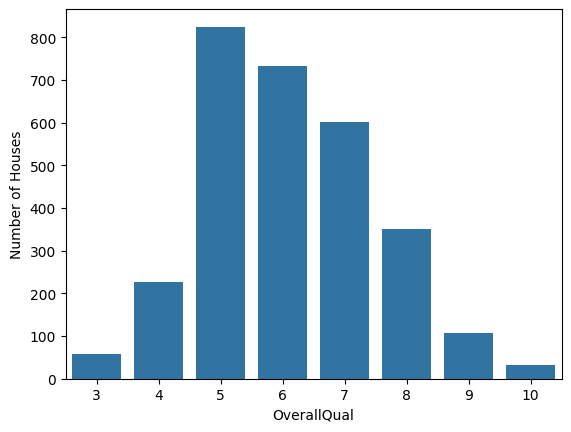

In [44]:
# Count houses in each overall-quality category.
sns.countplot(df,x="OverallQual")
plt.ylabel("Number of Houses")

<Axes: xlabel='OverallQual', ylabel='Count'>

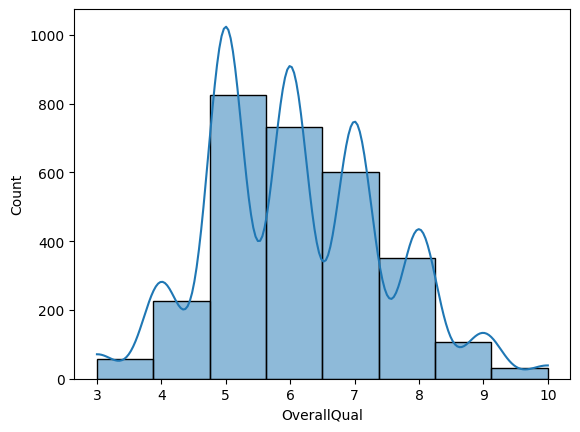

In [45]:
# Show the overall-quality distribution with a smoothed density curve.
sns.histplot(df,x="OverallQual",kde=True,bins=8)

In [46]:
# Compute mean overall quality as a compact numeric summary.
df[["OverallQual"]].mean()

OverallQual    6.102048
dtype: float64

The observed mean Overall Quality is **6.10** (median 6), corresponding to **Above Average**. Ratings are concentrated around the middle of the scale.

### Q2:how the Ovreall Quality change over the year of built and remodel date ?

In [47]:
import datetime
# Use the current year as the reference point when calculating house age.
datetime.datetime.now().year

2026

<Axes: xlabel='Age', ylabel='OverallQual'>

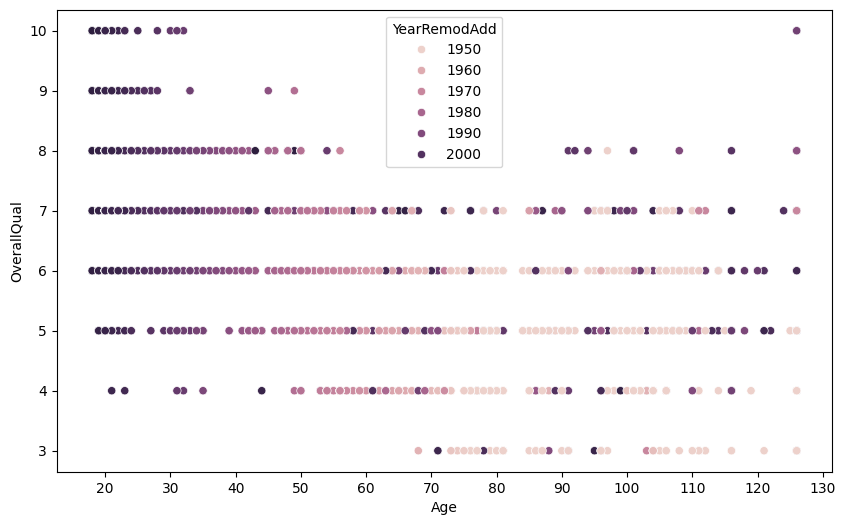

In [48]:
# Convert age to years since construction for easier interpretation.
df["Age"]=datetime.datetime.now().year-df[["YearBuilt"]]
plt.figure(figsize=(10,6))
plt.xticks(np.arange(0,160,step=10))
sns.scatterplot(df,x="Age",y="OverallQual",hue="YearRemodAdd")


* Houses that have an overall quality between very poor and below average are typically too old, usually more than 45 years old.
* Houses with very good overall quality or higher are considered relatively young, typically less than 50 years old.
* The age of houses that have an overall quality between average and very good varies, ranging from 15 to 150 years old. However, it is worth noting that there has been a noticeable trend of remodeling the older houses in the past 20 years (from 2000 onwards).

### Q3: What is the relationship between overall quality and sale price ?

             OverallQual  SalePrice
OverallQual     1.000000   0.813524
SalePrice       0.813524   1.000000


<Axes: xlabel='OverallQual', ylabel='SalePrice'>

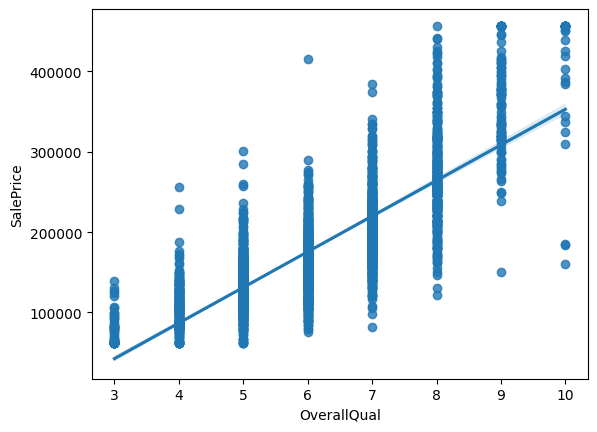

In [49]:
# Quantify and visualize the association between quality rating and sale price.
print(df[["OverallQual","SalePrice"]].corr())
sns.regplot(df,x="OverallQual",y="SalePrice")

Overall Quality has a strong positive association with SalePrice in this dataset (the observed correlation is about 0.80).

In [50]:
# Compare sale-price distributions across overall-quality ratings.
fig=px.box(df,x="OverallQual",y="SalePrice",color="OverallQual")
# Make the chart background transparent.
fig.update_layout(
    plot_bgcolor='rgba(0, 0, 0, 0)',
    paper_bgcolor='rgba(0, 0, 0, 0)'
)
fig.show()

## Q4 : is there a relationship between Ovreall quality and House style ?

,HouseStyle,OverallQual
0,1.5Fin,5.283439
1,1.5Unf,5.368421
2,1Story,6.021607
3,2.5Fin,6.375000
4,2.5Unf,6.583333
5,2Story,6.620848
6,SFoyer,5.373494
7,SLvl,5.976562


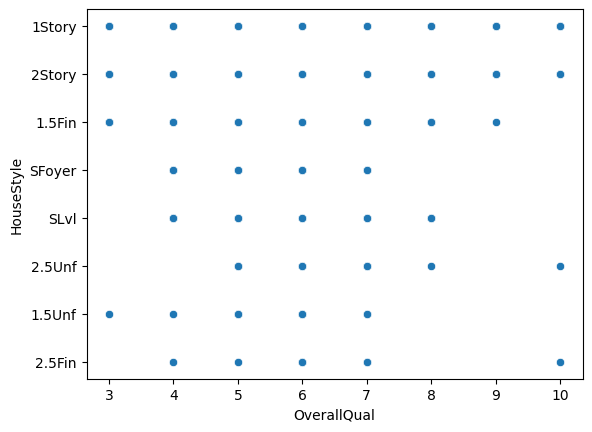

In [51]:
# Compare average overall quality across house styles.
sns.scatterplot(df,x="OverallQual",y="HouseStyle")
df[["OverallQual","HouseStyle"]].groupby("HouseStyle",as_index=False).mean()

In [52]:
fig=px.box(df,x="HouseStyle",y="OverallQual",color="HouseStyle")
fig.update_layout(plot_bgcolor='rgba(0, 0, 0, 0)',
                  paper_bgcolor="rgba(0, 0, 0, 0)"
)
fig.show()

In [42]:
df.columns

Index(['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF',
       '1stFlrSF', 'YearBuilt', 'FullBath', 'TotRmsAbvGrd', 'YearRemodAdd',
       'SalePrice', 'BsmtQual', 'BsmtCond', 'ExterQual', 'Foundation',
       'GarageFinish', 'HeatingQC', 'KitchenQual', 'BsmtFinType1',
       'Condition2', 'HouseStyle', 'Exterior1st', 'Age'],
      dtype='object')

## Q5: what is the impact of Total rooms above grade(TotRmsAbvGrd) on overall quality ?

Text(0.5, 0, 'Rooms above grade')

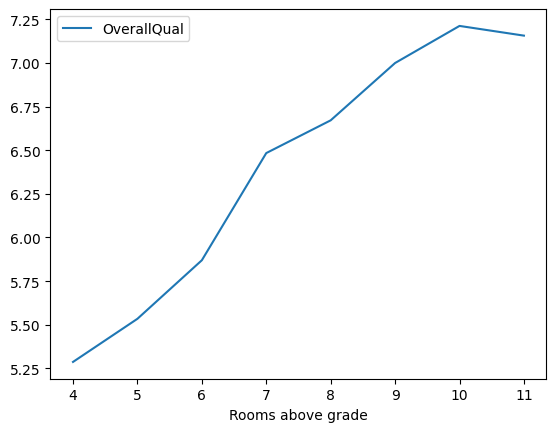

In [53]:
# Plot mean overall quality for each number of above-grade rooms.
df[["OverallQual","TotRmsAbvGrd"]].groupby("TotRmsAbvGrd").mean().plot(kind="line")
plt.xlabel("Rooms above grade")

<Axes: xlabel='TotRmsAbvGrd', ylabel='OverallQual'>

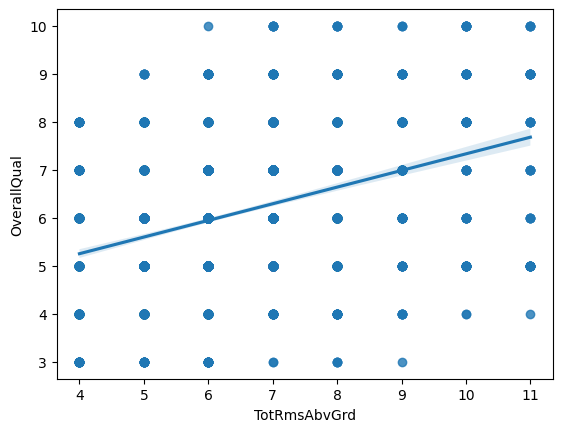

In [54]:
# Visualize the trend between above-grade room count and overall quality.
sns.regplot(df,x="TotRmsAbvGrd",y="OverallQual")

The overall quality **increases** as the number of TotRmsAbvGrd **increases**.

In [55]:
def vs_price(feature):
    fig,ax=plt.subplots(4,1,figsize=(8,12),sharex="all")
    plt.figure(figsize=(6,4))
    MSSubClass_Count=train_df[[feature]].value_counts().to_frame().reset_index().rename(columns={0:"Count"})
    value_bar=sns.barplot(MSSubClass_Count,x=feature,y="Count",ax=ax[0])
    grp_class=train_df[[feature,"SalePrice"]].groupby(feature,as_index=False).mean()
    barplot=sns.barplot(grp_class,x=feature,y="SalePrice",ax=ax[1])
    violin=sns.violinplot(train_df,x=feature,y="SalePrice",ax=ax[2])
    box=sns.boxplot(train_df,x=feature,y="SalePrice",ax=ax[3])
    
    return barplot,violin,box,value_bar

# 2- GrLivArea
Above grade (ground) living area square feet

In [56]:
# Convert above-grade living area from square feet to square metres.
df[["GrLivArea_m2"]]=df[["GrLivArea"]]*0.092903
df[["GrLivArea_m2"]].head()

,GrLivArea_m2
Order,
1,153.847368
2,83.241088
3,123.468087
4,196.025330
5,151.338987


## Q1: What is the relationship between GrLivArea and Overall Quality ?

In [57]:
# Measure the linear association between living area and overall quality.
df[["GrLivArea_m2","OverallQual"]].corr()

,GrLivArea_m2,OverallQual
GrLivArea_m2,1.000000,0.574281
OverallQual,0.574281,1.000000


Above-grade living area and Overall Quality have a positive correlation of **0.600**. The regression plot shows quality tending to rise with living area, though there is substantial variation at each quality level.

<Axes: xlabel='GrLivArea_m2', ylabel='OverallQual'>

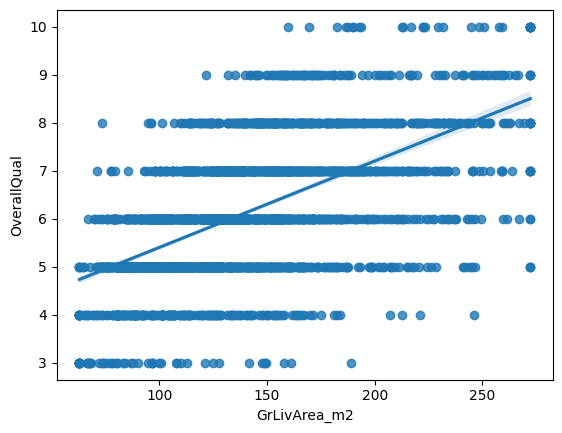

In [58]:
# Inspect the paired values and fit a linear trend for living area versus quality.
df[["GrLivArea_m2","OverallQual"]]
sns.regplot(df,x="GrLivArea_m2",y="OverallQual")

The overall quality increases as the  GrLivArea increases.


In [49]:
df.columns

Index(['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF',
       '1stFlrSF', 'YearBuilt', 'FullBath', 'TotRmsAbvGrd', 'YearRemodAdd',
       'SalePrice', 'BsmtQual', 'BsmtCond', 'ExterQual', 'Foundation',
       'GarageFinish', 'HeatingQC', 'KitchenQual', 'BsmtFinType1',
       'Condition2', 'HouseStyle', 'Exterior1st', 'Age', 'GrLivArea_m2'],
      dtype='object')

## Q2: What is the relationship between ground living area (GrLivArea_m2) and Total rooms above grade (TotRmsAbvGrd)  ?

              GrLivArea_m2  TotRmsAbvGrd
GrLivArea_m2       1.00000       0.81493
TotRmsAbvGrd       0.81493       1.00000


<Axes: xlabel='TotRmsAbvGrd'>

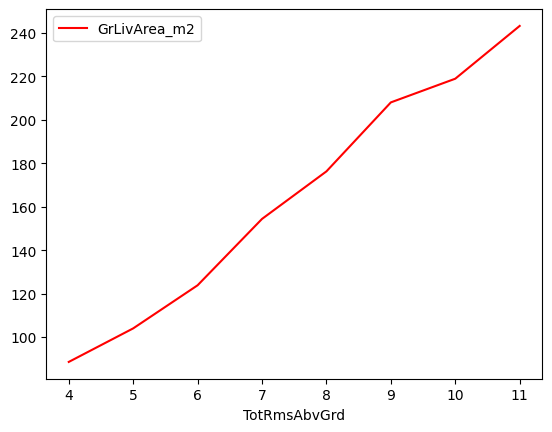

In [59]:
# Measure the living-area/room-count association and plot average area by room count.
print(df[["GrLivArea_m2","TotRmsAbvGrd"]].corr())
df[["GrLivArea_m2","TotRmsAbvGrd"]].groupby("TotRmsAbvGrd").mean().plot(kind="line",color="red")

In [ ]:
# Show each home's living area against its above-grade room count.
px.scatter(df,x="TotRmsAbvGrd",y="GrLivArea_m2",)

Above-grade room count and living area are strongly positively correlated (**r = 0.817**). The scatter and grouped means both show larger homes tending to have more rooms.

In [52]:
df.columns

Index(['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF',
       '1stFlrSF', 'YearBuilt', 'FullBath', 'TotRmsAbvGrd', 'YearRemodAdd',
       'SalePrice', 'BsmtQual', 'BsmtCond', 'ExterQual', 'Foundation',
       'GarageFinish', 'HeatingQC', 'KitchenQual', 'BsmtFinType1',
       'Condition2', 'HouseStyle', 'Exterior1st', 'Age', 'GrLivArea_m2'],
      dtype='object')

In [ ]:
# Check whether older houses tend to have less above-grade living area.
df[["GrLivArea_m2","Age"]].corr()

,GrLivArea_m2,Age
GrLivArea_m2,1.000000,-0.264179
Age,-0.264179,1.000000


<Axes: xlabel='HouseStyle', ylabel='GrLivArea_m2'>

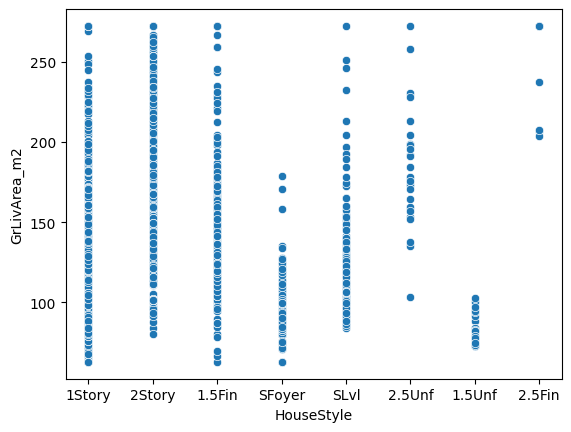

In [61]:
# Compare above-grade living-area distributions across house styles.
sns.scatterplot(df,x="HouseStyle",y="GrLivArea_m2")

Each style of houses has a different range of GrLivArea

<Axes: xlabel='Foundation', ylabel='GrLivArea_m2'>

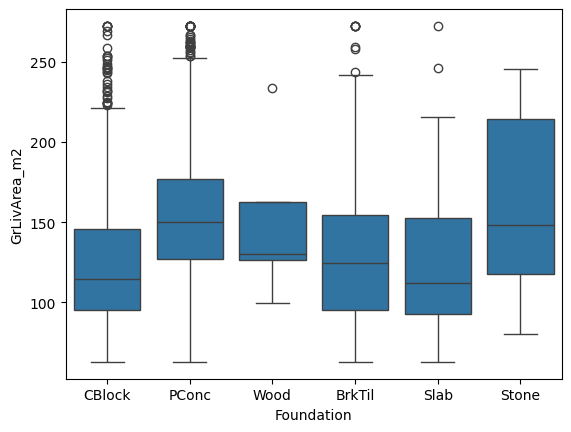

In [62]:
# Compare living-area distributions across foundation categories.
sns.boxplot(df,x="Foundation",y="GrLivArea_m2")

## Q3: What is the relationship with GrLivArea and GarageArea?

In [63]:
# Convert garage floor area from square feet to square metres.
df[["GarageArea_m2"]]=df[["GarageArea"]]*0.092903

In [64]:
# Measure association between garage area and above-grade living area.
df[["GarageArea_m2","GrLivArea_m2"]].corr()

,GarageArea_m2,GrLivArea_m2
GarageArea_m2,1.000000,0.485313
GrLivArea_m2,0.485313,1.000000


The correlation between GarageArea_m2 and GrLivArea_m2 is medium.

<Axes: xlabel='GarageArea_m2', ylabel='GrLivArea_m2'>

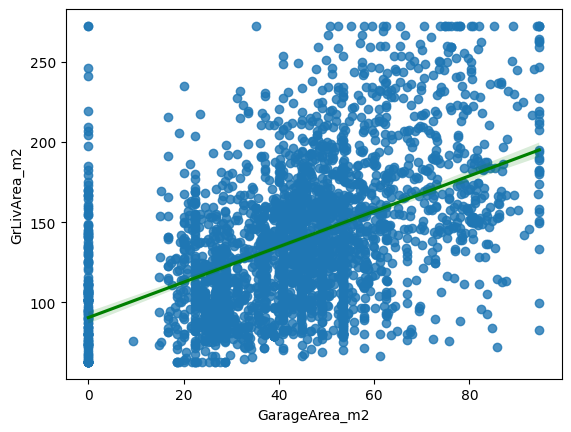

In [67]:
# Plot garage area against living area with a fitted linear trend.
sns.regplot(df,y="GrLivArea_m2",x="GarageArea_m2",line_kws={'color': 'green'})

the garage area increases as the GrLivArea increases.

In [68]:
# Summarize garage area as a fraction of above-grade living area.
Garage_GrLiv=df["GarageArea_m2"]/df["GrLivArea_m2"]
Garage_GrLiv.describe()

count    2930.000000
mean        0.324778
std         0.143194
min         0.000000
25%         0.252077
50%         0.313919
75%         0.399583
max         1.187661
dtype: float64

Garage area averages **33.0%** of above-grade living area (median **31.7%**) in this sample. This ratio summarizes relative size; it does not imply a fixed relationship for every house.

## Q4- what is the impact of GrLivArea on TotalBsmtSF ?

In [69]:
# Convert total basement area from square feet to square metres.
df["TotalBsmt_m2"]=df["TotalBsmtSF"]*0.092903

In [70]:
# Measure correlation between living area and basement area.
df[["GrLivArea_m2","TotalBsmt_m2"]].corr()

,GrLivArea_m2,TotalBsmt_m2
GrLivArea_m2,1.000000,0.408141
TotalBsmt_m2,0.408141,1.000000


<Axes: xlabel='TotalBsmt_m2', ylabel='GrLivArea_m2'>

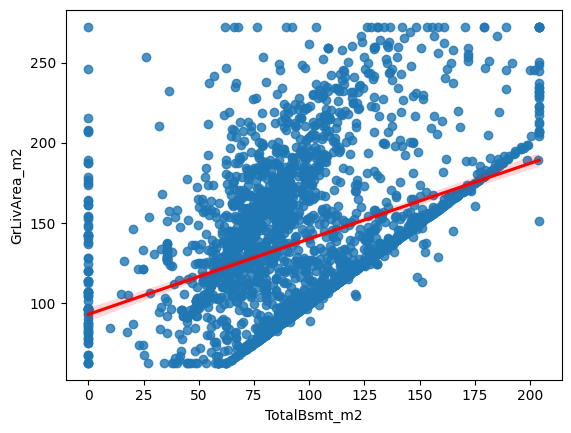

In [73]:
# Visualize the relationship between basement and above-grade living areas.
sns.regplot(df,x="TotalBsmt_m2",y="GrLivArea_m2",line_kws={'color': 'red'})

In [74]:
# Count homes where basement area equals above-grade living area.
df[df["GrLivArea_m2"]==df["TotalBsmt_m2"]]["TotalBsmt_m2"].count()

876

Above-grade living area and basement area have a moderate positive correlation (**r = 0.393**). They are exactly equal in **876 homes**; basement area is smaller in many other homes.

## Q5:How GrLivArea impact the price of a house ?

In [75]:
# Measure the relationship between living area and sale price.
df[["GrLivArea_m2","SalePrice"]].corr()

,GrLivArea_m2,SalePrice
GrLivArea_m2,1.000000,0.721044
SalePrice,0.721044,1.000000


Above-grade living area has a strong positive correlation with SalePrice (**r = 0.72**); the regression plot shows prices generally rising with area.

<Axes: xlabel='GrLivArea_m2', ylabel='SalePrice'>

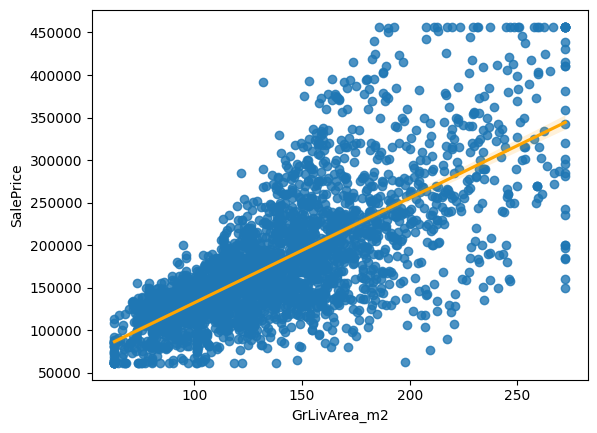

In [77]:
# Visualize sale price versus living area with a fitted linear trend.
sns.regplot(df,x="GrLivArea_m2",y="SalePrice",line_kws={'color': 'orange'})

The price is highly correlated with the GrLivArea; they increase accordingly to each other.

In [66]:
df.columns

Index(['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF',
       '1stFlrSF', 'YearBuilt', 'FullBath', 'TotRmsAbvGrd', 'YearRemodAdd',
       'SalePrice', 'BsmtQual', 'BsmtCond', 'ExterQual', 'Foundation',
       'GarageFinish', 'HeatingQC', 'KitchenQual', 'BsmtFinType1',
       'Condition2', 'HouseStyle', 'Exterior1st', 'Age', 'GrLivArea_m2',
       'GarageArea_m2', 'TotalBsmt_m2'],
      dtype='object')

# 3- GarageCars:
Size of garage in car capacity.

lets look at the relationship with GarageCars and:
* GarageArea
* Age
* BsmtQual
* HouseStyle
* SalePrice

# Q1- how impact the garage erea on the number of cars in the garage ?

In [78]:
# Measure the association between garage capacity and garage floor area.
df[["GarageCars","GarageArea_m2"]].corr()

,GarageCars,GarageArea_m2
GarageCars,1.00000,0.89715
GarageArea_m2,0.89715,1.00000


In [79]:
# Plot garage capacity against garage area for individual homes.
px.scatter(df,"GarageCars","GarageArea_m2")

Garage capacity and garage area are strongly positively correlated (**r = 0.883**), as expected: larger garages generally accommodate more cars.

## Q2 : What is the ralation between age and GarageArea ?

In [81]:
# Measure association between house age and garage capacity.
df[["Age","GarageCars"]].corr()

,Age,GarageCars
Age,1.000000,-0.552453
GarageCars,-0.552453,1.000000


In [82]:
# Compare garage capacity with house age for individual homes.
px.scatter(df,"Age","GarageCars")

<Axes: xlabel='GarageCars', ylabel='Age'>

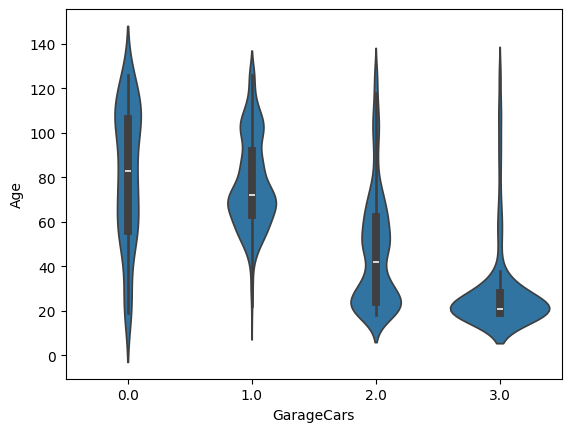

In [83]:
# Show the age distribution within each garage-capacity group.
sns.violinplot(df,x="GarageCars",y="Age")

Text(0, 0.5, 'Age')

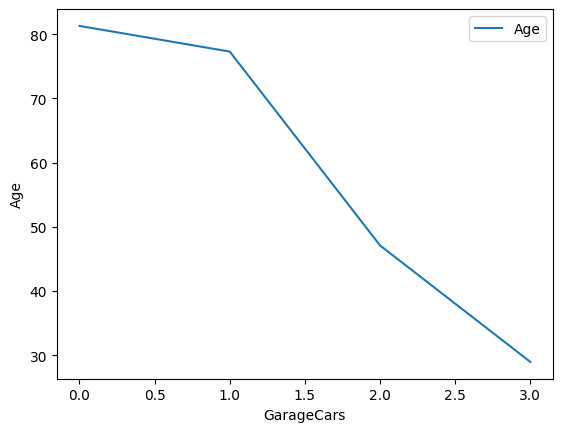

In [84]:
# Compare mean house age across garage-capacity groups.
df[["Age","GarageCars"]].groupby("GarageCars").mean().plot(kind="line")
plt.ylabel("Age")

House age and garage capacity have a moderate negative correlation (**r = -0.558**). Older homes in this sample tend to have fewer garage spaces; this is an association, not a causal effect.

## Q3- is there an impact of BsmtQual on the number of Cars in the Garage ?

NB:BsmtQual: Evaluates the height of the basement

       Ex	Excellent (100+ inches)	
       Gd	Good (90-99 inches)
       TA	Typical (80-89 inches)
       Fa	Fair (70-79 inches)
       Po	Poor (<70 inches
       NA	No Basement

In [85]:
# Compare median garage capacity across basement-quality categories.
dg=df[["GarageCars","BsmtQual"]].groupby("BsmtQual",as_index = False).median()
dg=dg.sort_values(by="GarageCars",ascending=False)
dg.style.bar(color="darkblue")

,BsmtQual,GarageCars
0,Ex,3.000000
2,Gd,2.000000
1,Fa,1.000000
3,Po,1.000000
4,TA,1.000000


The median garage capacity varies by basement quality: 3 cars for `Ex`, 2 for `Gd`, 1.5 for `Fa`, and 1 for `TA`. This grouped comparison does not account for category sample sizes.

In [86]:
# Keep derived metric-unit features and Age; remove their source-unit columns.
df.drop(columns=["TotalBsmtSF","GarageArea","GrLivArea"],inplace=True)
df.drop(columns=["YearBuilt"],inplace=True)

In [87]:
# Measure the association between garage capacity and sale price.
df[["SalePrice","GarageCars"]].corr()

,SalePrice,GarageCars
SalePrice,1.000000,0.671083
GarageCars,0.671083,1.000000


<Axes: xlabel='GarageCars', ylabel='SalePrice'>

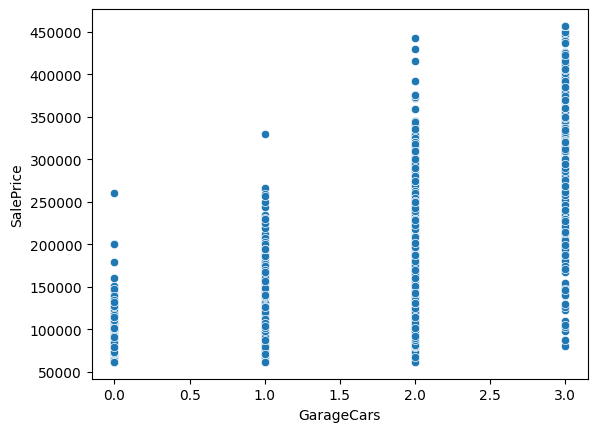

In [88]:
# Plot sale prices across garage-capacity values.
sns.scatterplot(df,x="GarageCars",y="SalePrice")

In [89]:
# Compare mean sale price for each garage-capacity group.
df[["SalePrice","GarageCars"]].groupby("GarageCars").mean().style.bar()

,SalePrice
GarageCars,
0.000000,106140.746709
1.000000,127449.297995
2.000000,183630.813026
3.000000,300207.409463


Garage capacity and SalePrice have a positive correlation (**r = 0.677**). Mean SalePrice rises across the observed groups, from about **$106 140** for 0-car garages to **$300 207** for 3-car garages.

# 5-1stFlrSF
First Floor square feet

## Q1- What is the average of the area First Floor?

In [90]:
# Convert first-floor area from square feet to square metres.
df[["1stFlr_m2"]]=df[["1stFlrSF"]]*0.092903

In [91]:
# Report the sample's mean first-floor area in square metres.
round(df["1stFlr_m2"].mean(),2)

107.34

## Q2- What is the relationship between  1stFlrSF and TotalBsmt ?

              1stFlr_m2  TotalBsmt_m2
1stFlr_m2      1.000000      0.793715
TotalBsmt_m2   0.793715      1.000000


<Axes: xlabel='1stFlr_m2', ylabel='TotalBsmt_m2'>

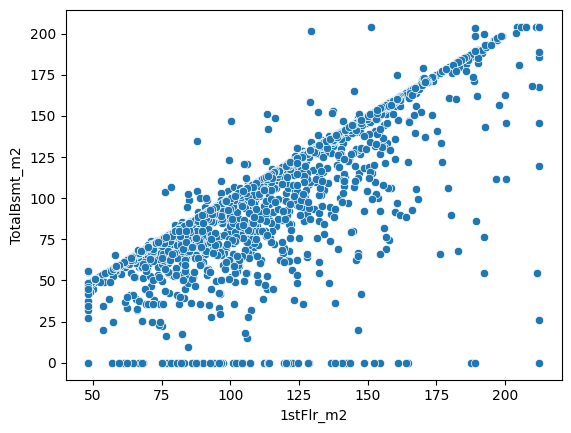

In [92]:
# Compare first-floor and basement areas in the same unit, then plot each home.
print(df[["1stFlr_m2","TotalBsmt_m2"]].corr())
sns.scatterplot(df,x="1stFlr_m2",y="TotalBsmt_m2")

First-floor and basement areas are strongly positively correlated (**r = 0.897**). Their areas often track one another, but they are not interchangeable for every home.

In [103]:
# Count homes whose first-floor and basement areas are equal.
df[df["1stFlr_m2"]==df["TotalBsmt_m2"]]['1stFlr_m2'].count()

1451

The two areas are equal in **1451 houses**.

In [94]:
# Count homes with more first-floor area than basement area.
df[df["1stFlr_m2"]>df["TotalBsmt_m2"]]['1stFlr_m2'].count()

1399

First-floor area exceeds basement area in **1399 houses**.

In [95]:
# Count homes with less first-floor area than basement area.
df[df["1stFlr_m2"]<df["TotalBsmt_m2"]]['1stFlr_m2'].count()

80

First-floor area is smaller than basement area in **80 houses**.

## Q3- How the 1stFlr_m2 Impact the OverallQuall ?

In [96]:
# Measure the association between first-floor area and overall quality.
df[["1stFlr_m2","OverallQual"]].corr()

,1stFlr_m2,OverallQual
1stFlr_m2,1.000000,0.482829
OverallQual,0.482829,1.000000


Text(0, 0.5, 'First-floor area (m^2)')

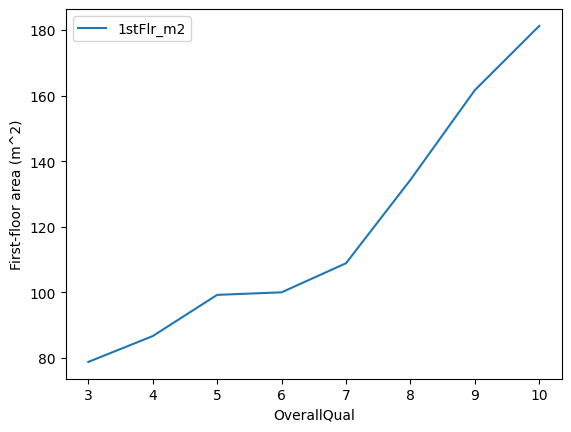

In [102]:
# Plot mean first-floor area for each overall-quality score.
df[["OverallQual","1stFlr_m2"]].groupby("OverallQual").mean().plot(kind="line")
plt.ylabel("First-floor area (m^2)")

<Axes: xlabel='1stFlr_m2', ylabel='OverallQual'>

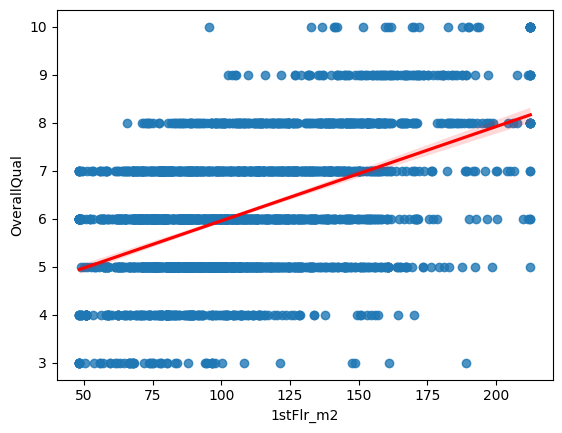

In [104]:
# Fit a linear trend to first-floor area versus overall quality.
ax=sns.regplot(df,x="1stFlr_m2",y="OverallQual",line_kws={"color":"red"})
ax

In [107]:
df[["1stFlr_m2","OverallQual"]].corr()

,1stFlr_m2,OverallQual
1stFlr_m2,1.000000,0.482829
OverallQual,0.482829,1.000000


First-floor area and Overall Quality have a moderate positive correlation (**r = 0.48**); the grouped means also rise with quality.

In [ ]:
# Remove the original square-foot field after retaining its metric conversion.
df.drop(columns=["1stFlrSF"],inplace=True)

## Q4- is the old houses have a small first flor erea?

1stFlr_m2,
Age, 
TotRmsAbvGrd, 
SalePrice, 
HouseStyle

In [110]:
df[["1stFlr_m2","Age"]].corr()

,1stFlr_m2,Age
1stFlr_m2,1.000000,-0.322011
Age,-0.322011,1.000000


First-floor area has a modest negative correlation with house age (**r = -0.323**). The relationship is not strong enough to claim a proportional decrease.

<Axes: xlabel='Age', ylabel='1stFlr_m2'>

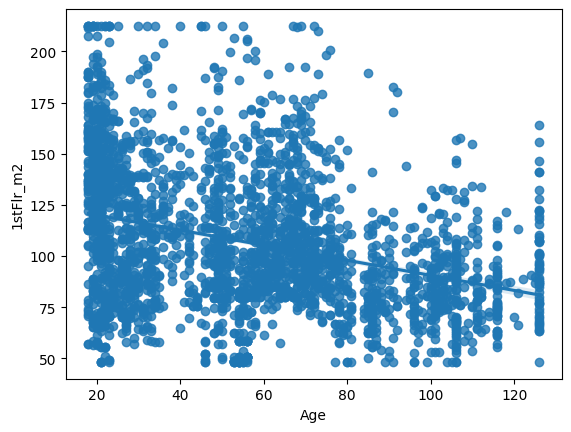

In [111]:
sns.regplot(df,y="1stFlr_m2",x="Age")

In [112]:
px.histogram(df,x="1stFlr_m2",y="Age",histfunc="avg")

The average first-floor area decreases inversely proportional to the age of the house.

In [92]:
df["TotRmsAbvGrd"].describe()

count    1318.000000
mean        6.352049
std         1.396016
min         3.000000
25%         5.000000
50%         6.000000
75%         7.000000
max        10.000000
Name: TotRmsAbvGrd, dtype: float64

In [ ]:
# Measure the association between above-grade room count and first-floor area.
df[["TotRmsAbvGrd","1stFlr_m2"]].corr()

,TotRmsAbvGrd,1stFlr_m2
TotRmsAbvGrd,1.00000,0.34071
1stFlr_m2,0.34071,1.00000


<Axes: xlabel='1stFlr_m2', ylabel='TotRmsAbvGrd'>

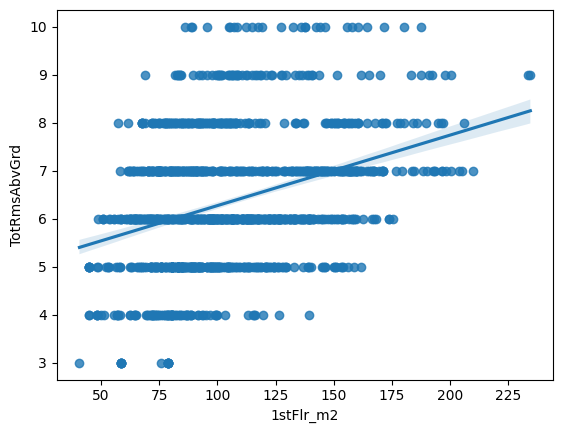

In [ ]:
# Plot room count against first-floor area with a fitted linear trend.
sns.regplot(df,y="TotRmsAbvGrd",x="1stFlr_m2")

Text(0, 0.5, 'First Floor Area in m2')

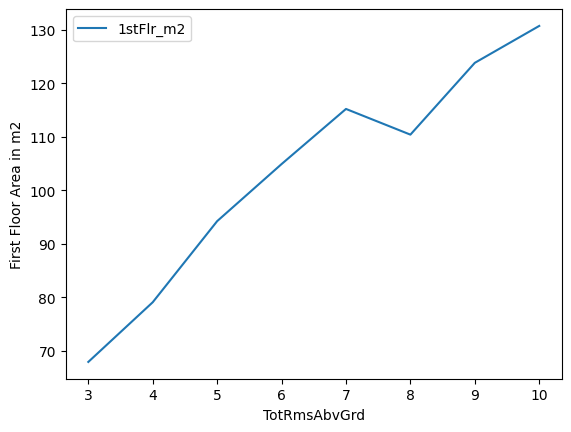

In [ ]:
# Compare mean first-floor area across above-grade room counts.
df[["TotRmsAbvGrd","1stFlr_m2"]].groupby("TotRmsAbvGrd").mean().plot(kind="line")
plt.ylabel("First-floor area (m^2)")

First-floor area and above-grade room count have a modest positive correlation (**r = 0.341**). The grouped mean plot rises with room count, although other floors and room layout also matter.

## Q5- is FtsFlr_m2 impacting the sale price ? 

In [114]:
# Measure the association between first-floor area and sale price.
df[["1stFlr_m2","SalePrice"]].corr()

,1stFlr_m2,SalePrice
1stFlr_m2,1.000000,0.643096
SalePrice,0.643096,1.000000


<Axes: xlabel='1stFlr_m2', ylabel='SalePrice'>

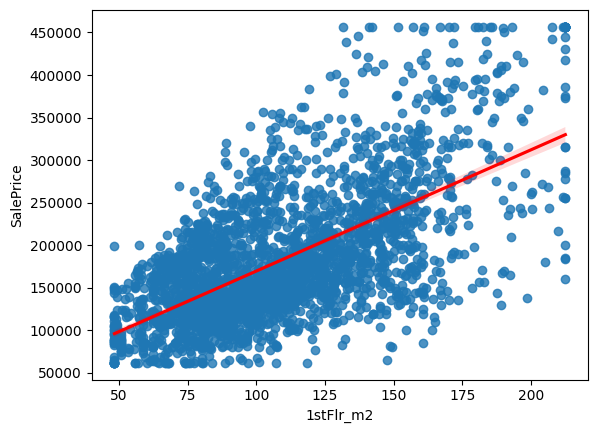

In [115]:
# Plot first-floor area versus sale price with a linear trend.
sns.regplot(df,x="1stFlr_m2",y="SalePrice",line_kws={"color":"red"})

First-floor area has a positive association with SalePrice (**r = 0.648**); the scatter plot shows higher prices tending to occur with larger first floors.

## Q6: How does house style relate to first-floor area?

In [116]:
# Compare mean first-floor area across house styles.
df[["HouseStyle","1stFlr_m2"]].groupby("HouseStyle").mean().sort_values(by="1stFlr_m2")\
.style.bar(color="orange")

,1stFlr_m2
HouseStyle,
1.5Unf,84.879115
1.5Fin,89.959099
2Story,91.272700
SFoyer,93.891354
2.5Unf,100.776529
SLvl,106.800708
1Story,121.595038
2.5Fin,124.002279


<Axes: xlabel='HouseStyle', ylabel='1stFlr_m2'>

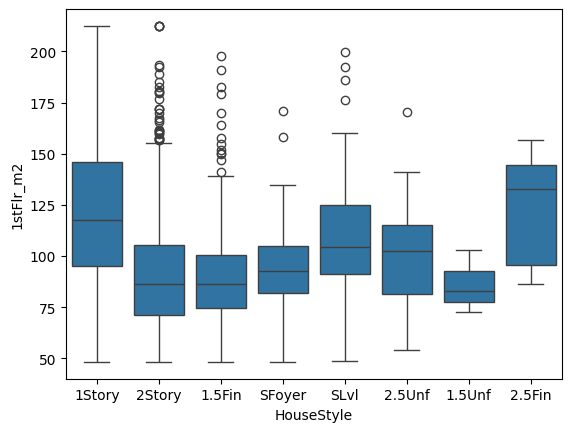

In [117]:
sns.boxplot(df,x="HouseStyle",y="1stFlr_m2")

In [101]:
df.columns

Index(['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'YearRemodAdd',
       'SalePrice', 'BsmtQual', 'BsmtCond', 'ExterQual', 'Foundation',
       'GarageFinish', 'HeatingQC', 'KitchenQual', 'BsmtFinType1',
       'Condition2', 'HouseStyle', 'Exterior1st', 'Age', 'GrLivArea_m2',
       'GarageArea_m2', 'TotalBsmt_m2', '1stFlr_m2'],
      dtype='object')

# 6- BasmtCond
Evaluates the general condition of the basement

       Ex	Excellent
       Gd	Good
       TA	Typical - slight dampness allowed
       Fa	Fair - dampness or some cracking or settling
       Po	Poor - Severe cracking, settling, or wetness
       NA	No Basement

lets get a look on the realationship between BsmtCond and BsmntQual. 

In [ ]:
# Inspect basement quality/condition combinations and visualize their counts.

bsm = pd.DataFrame(df[["BsmtCond","BsmtQual"]].groupby("BsmtCond").count())
#.sort(values="BsmtQual",ascending=False).style.bar(color="green")
bsm.columns = ["Count"]
bsm


,Count
BsmtCond,
Ex,3
Fa,104
Gd,122
Po,5
TA,2616


In [140]:
# Compare average sale price across basement-condition categories.
df[["BsmtCond","SalePrice"]].groupby("BsmtCond",as_index=False).mean().sort_values(by="SalePrice").style.bar()

,BsmtCond,SalePrice
1,Fa,124111.245769
3,Po,124214.414000
4,TA,182987.283146
0,Ex,195000.000000
2,Gd,214535.994836


* The sale price increases as the BsmtCond increases. 

# 7- Foundation
Type of foundation
		
       BrkTil	Brick & Tile
       CBlock	Cinder Block
       PConc	Poured Contrete	
       Slab	Slab
       Stone	Stone
       Wood	Wood

## Q: What is the relationship between Foundation and : 
* OverallQual ?
* Age ?
* BsmtCond ?
* HouseStyle ?
* GrLivArea_m2 ?
* SalePrice ?

### OverallQual

In [141]:
# Compare mean overall quality across foundation types.
df[["Foundation","OverallQual"]].groupby("Foundation",as_index=False).mean().sort_values(by="OverallQual").style.bar()

,Foundation,OverallQual
3,Slab,4.448980
0,BrkTil,5.344051
1,CBlock,5.439711
4,Stone,5.545455
5,Wood,6.400000
2,PConc,6.976336


<Axes: xlabel='Foundation', ylabel='OverallQual'>

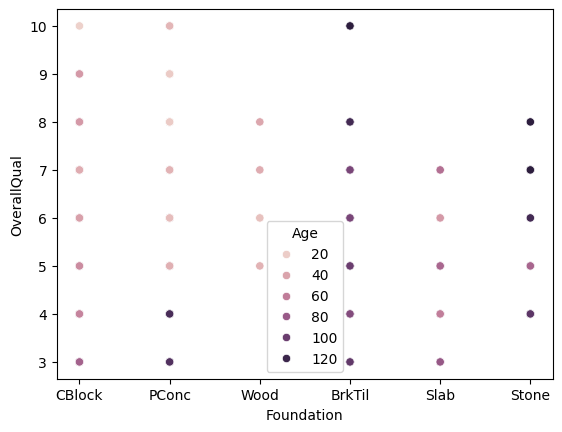

In [142]:
# Visualize overall quality by foundation type, with age shown by color.
sns.scatterplot(df,x="Foundation",y="OverallQual",hue="Age")

Text(0.5, 1.0, 'Mean house age by overall quality and foundation type')

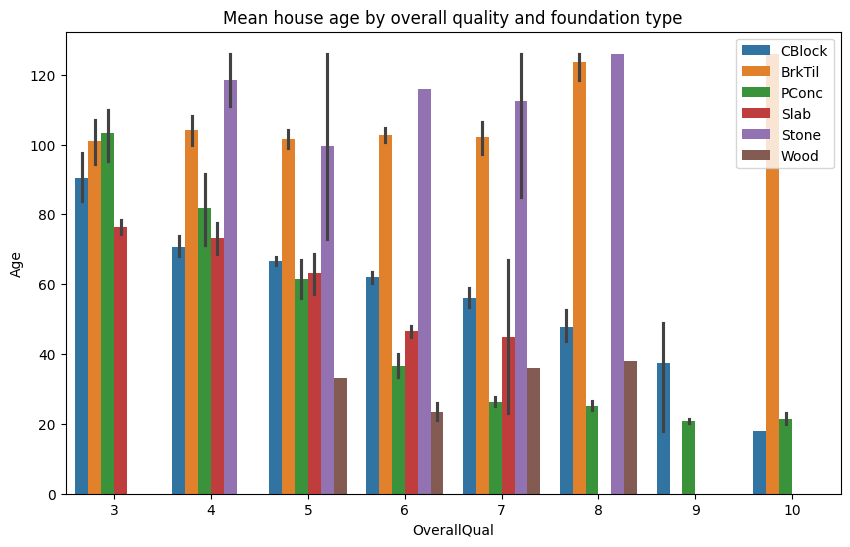

In [143]:
# Compare age distributions across quality ratings and foundation categories.
plt.figure(figsize=(10,6))
sns.barplot(df,y="Age",hue="Foundation",x="OverallQual")
plt.legend(loc="upper right")
plt.title("Mean house age by overall quality and foundation type")



* Cinder Block and Poured Concrete Foundations:

   * As the age of houses with these foundations decreases, their overall quality tends to increase.
   * This suggests that newer houses with cinder block and poured concrete foundations generally have      better quality.
* Brick and Tile Foundations:

   * Houses with brick and tile foundations are old but many of them are still in good condition.
   * This implies that despite their age, houses with brick and tile foundations have maintained a         good quality.
* Woody Foundations:

     * Houses with woody foundations, specifically those aged 25 or less, have a good quality.
     * This suggests that newer houses with woody foundations tend to have a high overall quality.
     
* Stone Foundations:
   * Houses with stone foundations have a quality that is below the "above average" range.
   * This implies that houses with stone foundations generally have a lower overall quality compared       to other foundation types.

## BsmtCond

In [145]:
# Show basement-condition counts within each foundation type.
#px.treemap(df,names="Foundation",path=["Foundation","BsmtCond"])

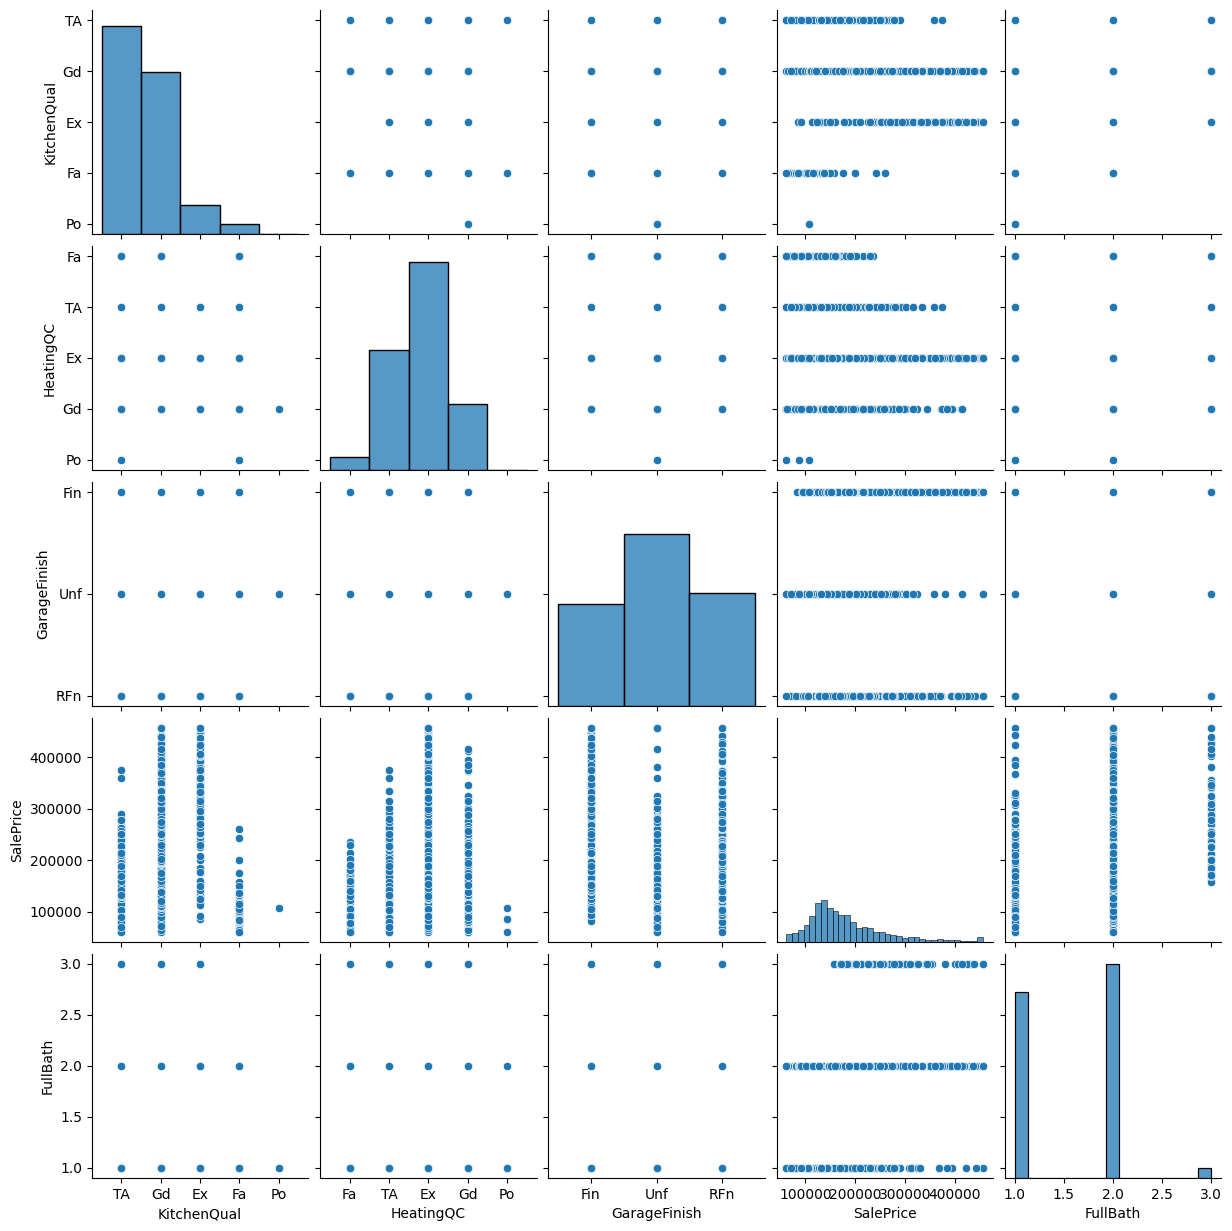

In [146]:
# Explore pairwise distributions for key categorical features, price, and bathroom count.
ax=sns.pairplot(df,vars=["KitchenQual","HeatingQC","GarageFinish","SalePrice","FullBath"])
ax

In [147]:
# Summarize numeric features for houses above the $100,000 sale-price threshold.
df.query("SalePrice>100000").describe()

,OverallQual,GarageCars,FullBath,TotRmsAbvGrd,YearRemodAdd,SalePrice,Age,GrLivArea_m2,GarageArea_m2,TotalBsmt_m2,1stFlr_m2
count,2678.000000,2678.000000,2678.000000,2678.000000,2678.000000,2678.000000,2678.000000,2678.000000,2678.000000,2678.000000,2678.000000
mean,6.271098,1.842793,1.608290,6.546303,1986.259149,189208.342830,51.524645,142.899239,45.862123,101.112080,110.184703
std,1.306743,0.692242,0.537741,1.502551,19.967775,72885.532918,28.735834,43.461518,18.296864,36.749152,33.775080
min,3.000000,0.000000,1.000000,4.000000,1950.000000,100500.000000,18.000000,62.942712,0.000000,0.000000,48.309560
25%,5.000000,1.000000,1.000000,6.000000,1968.000000,137000.000000,24.000000,111.111988,34.559916,77.295296,84.263021
50%,6.000000,2.000000,2.000000,6.000000,1995.000000,169000.000000,49.000000,137.821600,44.965052,95.875896,103.679748
75%,7.000000,2.000000,2.000000,7.000000,2004.000000,220000.000000,69.000000,165.506695,54.626964,124.373891,132.270646
max,10.000000,3.000000,3.000000,11.000000,2009.000000,456666.370000,126.000000,272.267106,94.680234,204.117181,212.451509


In [149]:
# Export the curated feature table for use in the modeling notebooks.
df.to_csv("../datasets/house_price_cleaned_vf.csv")

## Summary

- This EDA examines selected numeric and categorical house features from the preprocessed, no-outlier dataset, retaining records with a known `SalePrice`.
- Overall Quality has a strong positive association with SalePrice (about 0.80 in the notebook's correlation calculation). Larger living and first-floor areas, more rooms, and greater garage capacity also tend to occur with higher quality or sale prices in the plotted comparisons.
- Age-related patterns are mixed: some older homes have lower quality or garage capacity, while remodeling and foundation type distinguish many exceptions.
- Living, garage, basement, and first-floor areas are converted from square feet to square metres for comparison. The selected feature table is exported as `house_price_cleaned.csv` for downstream modeling.
- These are exploratory associations, not evidence of causation. Group averages and plots can also be affected by uneven category sizes and the preprocessing used to create the dataset.